In [1]:
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds


In [2]:

# 1. پچ رفع باگ ویندوز در خواندن فایل‌های ZIP
_orig_getinfo = zipfile.ZipFile.getinfo


def _patched_getinfo(self, name):
    if isinstance(name, str):
        name = name.replace("\\", "/")
    return _orig_getinfo(self, name)


zipfile.ZipFile.getinfo = _patched_getinfo


# 2. کد اصلی شما
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 10

(train_ds, val_ds, test_ds), ds_info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True,
)

class_names = ds_info.features["label"].names

print("Classes:", class_names)
print("Train size:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val size:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test size:", tf.data.experimental.cardinality(test_ds).numpy())


Classes: ['cat', 'dog']
Train size: 18610
Val size: 2326
Test size: 2326


In [13]:


IMG_SIZE = (160, 160)   # VGG16 expects 224x224 images
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
EPOCHS = 10
(train_ds, val_ds, test_ds), ds_info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    
    with_info=True
)

class_names = ds_info.features["label"].names

print("Classes:", class_names)
print("Train size:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val size:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test size:", tf.data.experimental.cardinality(test_ds).numpy())



Classes: ['cat', 'dog']
Train size: 18610
Val size: 2326
Test size: 2326


In [20]:
# demo for speed run
IMG_SIZE = (160, 160)
TRAIN_SIZE = 3000
VAL_SIZE   = 500
TEST_SIZE  = 500

train_ds = train_ds.take(TRAIN_SIZE)
val_ds   = val_ds.take(VAL_SIZE)
test_ds  = test_ds.take(TEST_SIZE)


In [ ]:
# ------------------------------------------------------------
# Data augmentation pipeline
# These layers randomly transform images during training only.
# ------------------------------------------------------------
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])


In [ ]:
# ------------------------------------------------------------
#Preprocessing function
#  - Resize images to 224x224
#  - Convert to float32
#  - Apply VGG16 preprocess_input (matches ImageNet training)
# ------------------------------------------------------------
from tensorflow.keras.applications.vgg16 import preprocess_input

def preprocess(image, label, augment=False):
    # Resize
    image = tf.image.resize(image, IMG_SIZE)

    # Apply augmentation only on training data
    if augment:
        image = data_augmentation(image)

    # VGG16-specific normalization
    image = preprocess_input(image)

    # Ensure label is float (needed for binary crossentropy)
    label = tf.cast(label, tf.float32)
    return image, label


In [ ]:
# ------------------------------------------------------------
# Build tf.data pipelines
#    - Training: shuffle, augment, batch, prefetch
#    - Validation/Test: batch, prefetch
# ------------------------------------------------------------
train_ds = (train_ds
            .shuffle(1000)
            .map(lambda x, y: preprocess(x, y, augment=True), num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

val_ds = (val_ds
          .map(lambda x, y: preprocess(x, y, augment=False), num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(AUTOTUNE))

test_ds = (test_ds
           .map(lambda x, y: preprocess(x, y, augment=False), num_parallel_calls=AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(AUTOTUNE))


In [ ]:
# ------------------------------------------------------------
# Build the model
#    - Load VGG16 pretrained on ImageNet
#    - include_top=False removes VGG's original classifier
#    - Freeze all VGG16 convolutional layers
#    - Add our custom classifier head:
#         GlobalAveragePooling2D
#         Dense(128, relu)
#         Dense(1, sigmoid)
# ------------------------------------------------------------
base_model = tf.keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=IMG_SIZE + (3,)
)

# Freeze the base model so only the new head trains
base_model.trainable = False

# Build the full model
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = base_model(inputs, training=False)  # training=False important when frozen
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)

model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# ------------------------------------------------------------
# Compile the model
# ------------------------------------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------------------------
# Train the model (~10 epochs)
# ------------------------------------------------------------
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)


Epoch 1/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 52s 441ms/step - accuracy: 0.6148 - loss: 1.9733 - val_accuracy: 0.9200 - val_loss: 0.2449
Epoch 2/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 28s 287ms/step - accuracy: 0.8999 - loss: 0.2685 - val_accuracy: 0.9540 - val_loss: 0.1398
Epoch 3/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 289ms/step - accuracy: 0.9322 - loss: 0.2030 - val_accuracy: 0.9600 - val_loss: 0.1235
Epoch 4/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 40s 290ms/step - accuracy: 0.9333 - loss: 0.1730 - val_accuracy: 0.9680 - val_loss: 0.1129
Epoch 5/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 41s 295ms/step - accuracy: 0.9473 - loss: 0.1411 - val_accuracy: 0.9740 - val_loss: 0.1062
Epoch 6/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 28s 289ms/step - accuracy: 0.9500 - loss: 0.1448 - val_accuracy: 0.9760 - val_loss: 0.1034
Epoch 7/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 28s 289ms/step - accuracy: 0.9512 - loss: 0.1231 - val_accuracy: 0.9760 - val_loss: 0.1042
Epoch 8/10
94/94 ━━━━━━━━━━━━━━━━━━━━ 29s 293ms/step - accuracy: 0.9561 - loss: 0.1098 - val_accu

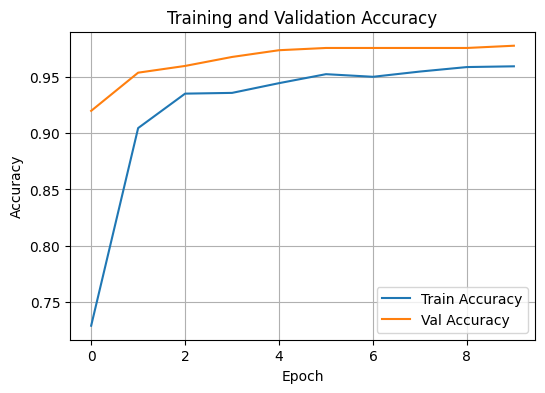

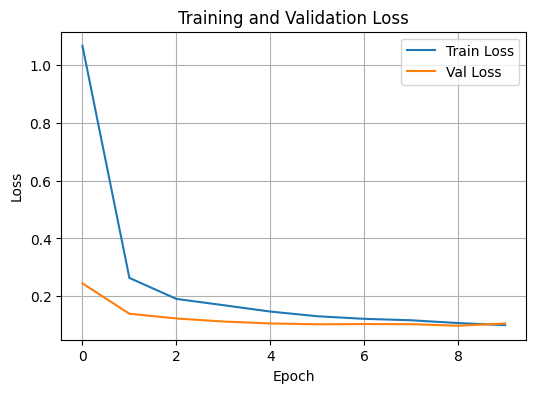

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.9813 - loss: 0.0639
Test accuracy: 0.9740, Test loss: 0.0878


In [ ]:
# ------------------------------------------------------------
#  Plot training & validation accuracy and loss
# ------------------------------------------------------------
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(EPOCHS)

plt.figure(figsize=(6,4))
plt.plot(epochs_range, acc, label="Train Accuracy")
plt.plot(epochs_range, val_acc, label="Val Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(epochs_range, loss, label="Train Loss")
plt.plot(epochs_range, val_loss, label="Val Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# Evaluate on the test set
# ------------------------------------------------------------
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}, Test loss: {test_loss:.4f}")



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 899ms/step


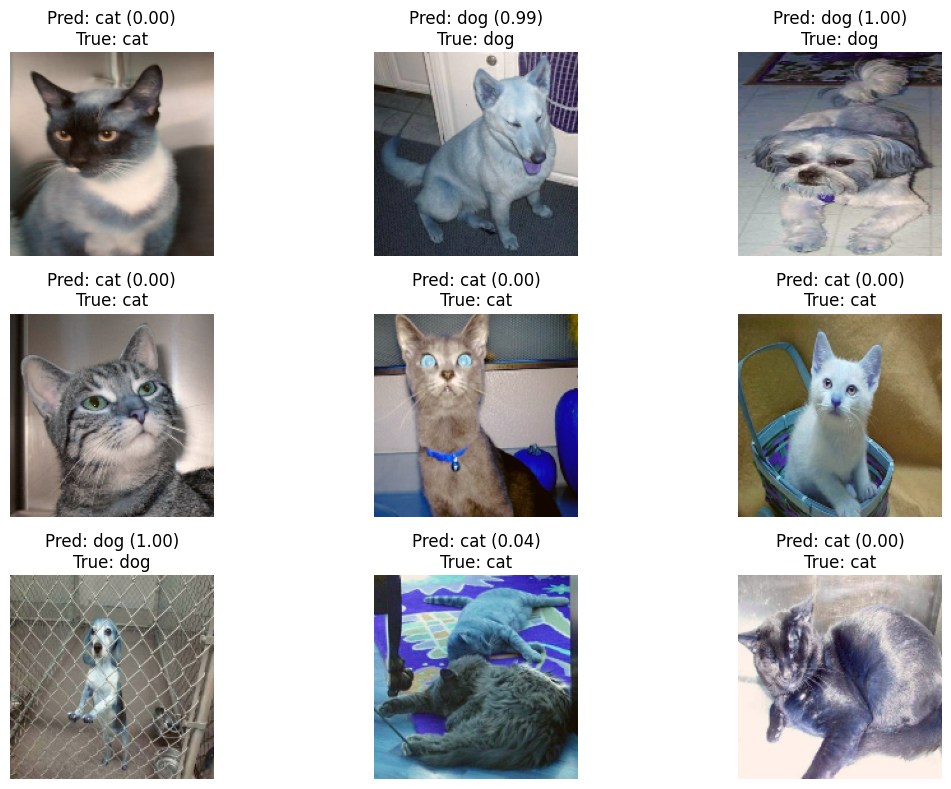

In [ ]:
# ------------------------------------------------------------
#  Predict on a few samples
#    We'll take one batch from test_ds, run predictions,
#    then show images with predicted labels.
# ------------------------------------------------------------
# Get one batch of images and labels from the test dataset
for images, labels in test_ds.take(1):
    preds = model.predict(images)
    preds = tf.squeeze(preds)  # shape: (batch_size,)

    plt.figure(figsize=(12, 8))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        # Convert back to a displayable image:
        # preprocess_input makes values not in [0,255], so we rescale for plotting.
        img_display = images[i].numpy()
        img_display = (img_display - img_display.min()) / (img_display.max() - img_display.min())

        plt.imshow(img_display)

        pred_label = 1 if preds[i] > 0.5 else 0
        true_label = int(labels[i].numpy())

        plt.title(
            f"Pred: {class_names[pred_label]} ({preds[i]:.2f})\n"
            f"True: {class_names[true_label]}"
        )
        plt.axis("off")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# Done!
# A clean transfer-learning pipeline with VGG16.
# ------------------------------------------------------------